In [88]:
!git clone https://github.com/Tralaiday/NLP.git temp_repo

import sys
import os

src_path = os.path.abspath('temp_repo/Lab6/src')
if src_path not in sys.path:
    sys.path.append(src_path)

print("Đã cấu hình đường dẫn import thành công từ:", src_path)

fatal: destination path 'temp_repo' already exists and is not an empty directory.
Đã cấu hình đường dẫn import thành công từ: /content/temp_repo/Lab6/src


In [89]:
# 1. Đi vào thư mục repo và kéo (pull) code mới nhất về
!git -C temp_repo pull

# 2. Reload module trong Python để áp dụng thay đổi mới ngay lập tức
import importlib
import attention_numpy

importlib.reload(attention_numpy)
from attention_numpy import scaled_dot_product_attention

print("Đã cập nhật và nạp lại mô-đun 'attention_numpy' thành công!")

Already up to date.
Đã cập nhật và nạp lại mô-đun 'attention_numpy' thành công!


In [90]:
!cd temp_repo/Lab6/src
!git pull origin main

fatal: not a git repository (or any of the parent directories): .git


In [91]:
from attention_numpy import scaled_dot_product_attention

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Experiment 1: Attention distribution

In [92]:
query_tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]

# Embeddings: [sentiment, topic, context/time]
embedding_dict = {
    "The": [0.0, 0.0, 0.1],
    "movie": [0.1, 1.0, 0.2],
    "was": [0.0, 0.0, 0.0],
    "surprisingly": [0.5, 0.2, 0.1],
    "good": [1.0, 0.3, 0.1],
    "despite": [0.0, 0.1, 0.5],
    "a": [0.0, 0.0, 0.0],
    "very": [0.2, 0.1, 0.0],
    "slow": [-0.8, 0.2, 0.2],
    "beginning": [-0.1, 0.2, 1.0]
}
print("Number of tokens:", len(query_tokens))

# Tạo K
K = np.array([embedding_dict[token] for token in query_tokens], dtype = float)

# Tạo Q
Q = np.array([1.0, 0.0, 0.0], dtype = float)

# Tạo V
V = K.copy()

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

S, A = scaled_dot_product_attention(Q, K, V)[:2]

df_experiment_1 = pd.DataFrame(
    {
        "Token": query_tokens,
        "Score": S,
        "Attention": A
    }
)

print(df_experiment_1)


Number of tokens: 10
Q shape: (3,)
K shape: (10, 3)
V shape: (10, 3)
          Token     Score  Attention
0           The  0.000000   0.091981
1         movie  0.057735   0.097448
2           was  0.000000   0.091981
3  surprisingly  0.288675   0.122763
4          good  0.577350   0.163847
5       despite  0.000000   0.091981
6             a  0.000000   0.091981
7          very  0.115470   0.103240
8          slow -0.461880   0.057957
9     beginning -0.057735   0.086821


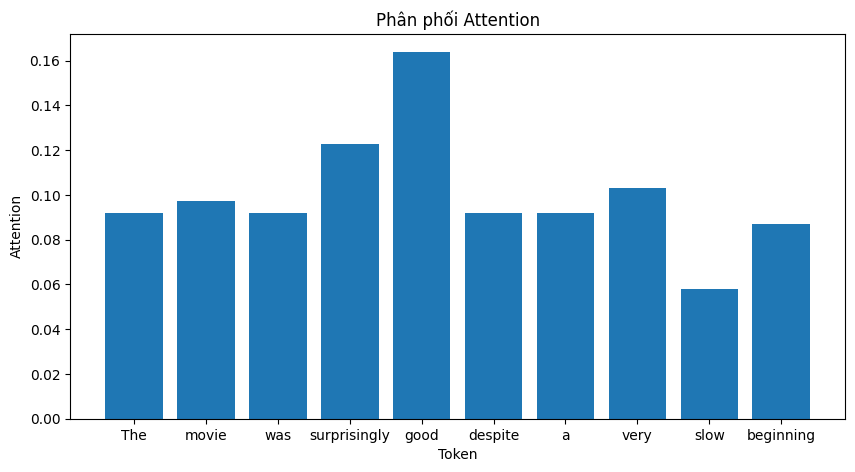

In [93]:
plt.figure(figsize = (10, 5))
plt.bar(query_tokens, A)

plt.title("Phân phối Attention")
plt.xlabel("Token")
plt.ylabel("Attention")
plt.show()

# Experiment 2: Query thay đổi

          Token     Score  Attention
0           The  0.000000   0.087287
1         movie  0.577350   0.155485
2           was  0.000000   0.087287
3  surprisingly  0.115470   0.097971
4          good  0.173205   0.103794
5       despite  0.057735   0.092475
6             a  0.000000   0.087287
7          very  0.057735   0.092475
8          slow  0.115470   0.097971
9     beginning  0.115470   0.097971


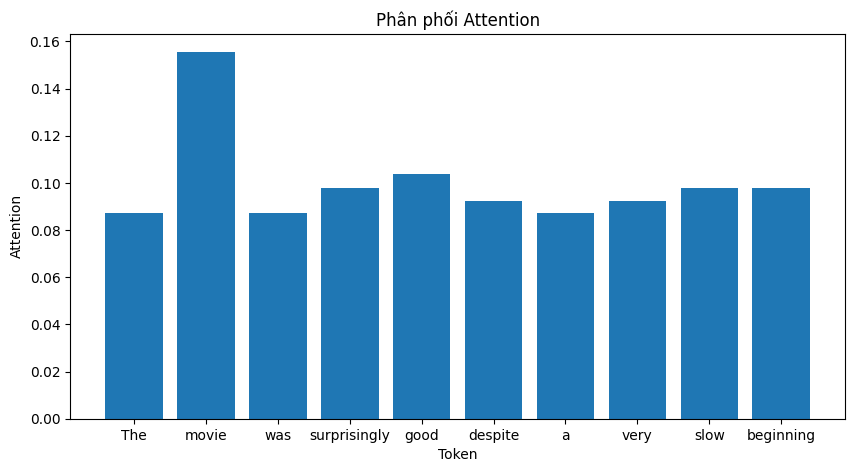

In [94]:
new_Q = np.array([0.0, 1.0, 0.0], dtype = float)

new_S, new_A = scaled_dot_product_attention(new_Q, K, V)[:2]

df_experiment_2 = pd.DataFrame(
    {
        "Token": query_tokens,
        "Score": new_S,
        "Attention": new_A
    }
)

print(df_experiment_2)

plt.figure(figsize = (10, 5))
plt.bar(query_tokens, new_A)

plt.title("Phân phối Attention")
plt.xlabel("Token")
plt.ylabel("Attention")
plt.show()